In [39]:
import pandas as pd
import seaborn as sns
import numpy as np

import matplotlib
import matplotlib.pyplot as plt
plt.style.use('ggplot')
from matplotlib.pyplot import figure

%matplotlib inline
matplotlib.rcParams['figure.figsize'] = (12,8)


df = pd.read_csv('movies_lib.csv')
df.head()

,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime
0,The Shining,R,Drama,1980,"June 13, 1980 (United States)",8.4,927000.0,Stanley Kubrick,Stephen King,Jack Nicholson,United Kingdom,19000000.0,46998772.0,Warner Bros.,146.0
1,The Blue Lagoon,R,Adventure,1980,"July 2, 1980 (United States)",5.8,65000.0,Randal Kleiser,Henry De Vere Stacpoole,Brooke Shields,United States,4500000.0,58853106.0,Columbia Pictures,104.0
2,Star Wars: Episode V - The Empire Strikes Back,PG,Action,1980,"June 20, 1980 (United States)",8.7,1200000.0,Irvin Kershner,Leigh Brackett,Mark Hamill,United States,18000000.0,538375067.0,Lucasfilm,124.0
3,Airplane!,PG,Comedy,1980,"July 2, 1980 (United States)",7.7,221000.0,Jim Abrahams,Jim Abrahams,Robert Hays,United States,3500000.0,83453539.0,Paramount Pictures,88.0
4,Caddyshack,R,Comedy,1980,"July 25, 1980 (United States)",7.3,108000.0,Harold Ramis,Brian Doyle-Murray,Chevy Chase,United States,6000000.0,39846344.0,Orion Pictures,98.0


In [40]:
for col in df.columns:
  pct_missing = np.mean(df[col].isnull())
  total_missing = df[col].isnull().sum()
  print('{} - {}%'.format(col, pct_missing))
  print(total_missing)



name - 0.0%
0
rating - 0.010041731872717789%
77
genre - 0.0%
0
year - 0.0%
0
released - 0.0002608242044861763%
2
score - 0.0003912363067292645%
3
votes - 0.0003912363067292645%
3
director - 0.0%
0
writer - 0.0003912363067292645%
3
star - 0.00013041210224308815%
1
country - 0.0003912363067292645%
3
budget - 0.2831246739697444%
2171
gross - 0.02464788732394366%
189
company - 0.002217005738132499%
17
runtime - 0.0005216484089723526%
4


In [41]:
# Changing Column Data Type

df['budget'] = df['budget'].astype('Int64')
df['gross'] = df['gross'].astype('Int64')
df.dtypes

,0
name,object
rating,object
genre,object
year,int64
released,object
score,float64
votes,float64
director,object
writer,object
star,object


In [ ]:
# Extracting the 4-digit year from the 'released' column using regex
df['year_released'] = df['released'].astype(str).str.extract(r'(\d{4})')
display(df[['released', 'year_released']].head())

,released,year_released
0,"June 13, 1980 (United States)",1980
1,"July 2, 1980 (United States)",1980
2,"June 20, 1980 (United States)",1980
3,"July 2, 1980 (United States)",1980
4,"July 25, 1980 (United States)",1980


In [21]:
df.sort_values(by=['gross'], inplace=False, ascending=False)
df.isna().sum()

,0
name,0
rating,0
genre,0
year,0
released,0
score,3
votes,3
director,0
writer,0
star,0


In [3]:
## set display to show full data
pd.set_option('display.max_rows', None)

In [5]:
# drop Duplicates - Not needed for this project

#  df['company'].drop_duplicates().sort_values(ascending=False)
#  df.drop_duplicates()

,company
7129,thefyzz
5664,micro_scope
6412,iDeal Partners Film Fund
4007,i5 Films
6793,i am OTHER
6420,erbp
3776,double A Films
524,Zupnik-Curtis Enterprises
3330,Zucker Brothers Productions
146,Zoetrope Studios


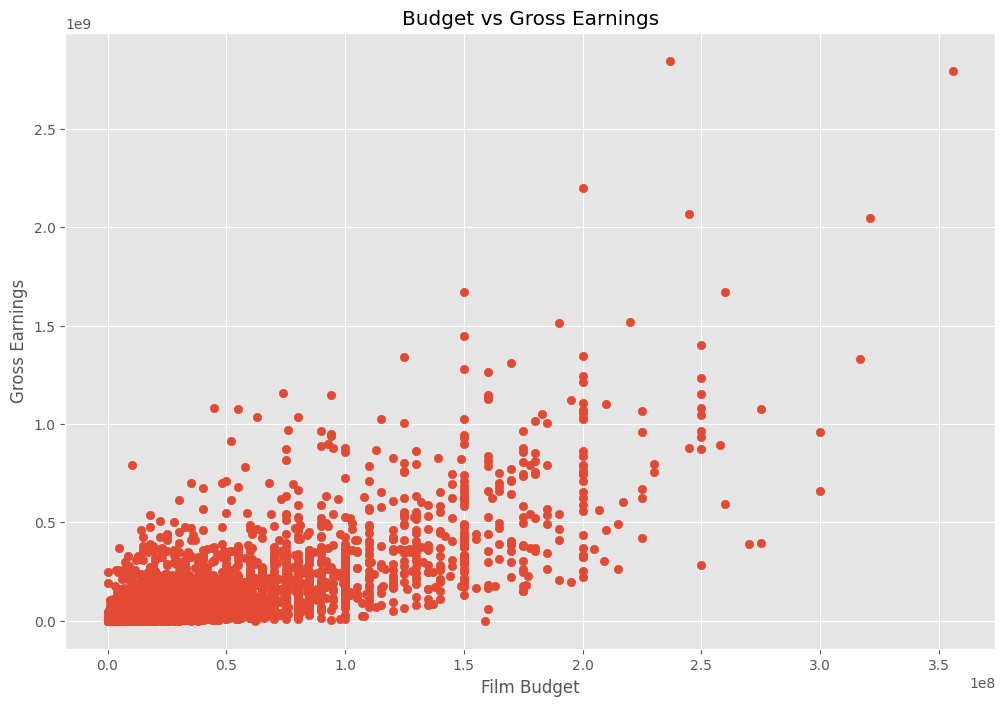

In [42]:
# Correlation - Budget Vs Gross with Scatterplot
plt.scatter(x=df['budget'], y=df['gross'])

plt.title('Budget vs Gross Earnings')
plt.xlabel("Film Budget")
plt.ylabel("Gross Earnings")

plt.show()

<Axes: xlabel='budget', ylabel='gross'>

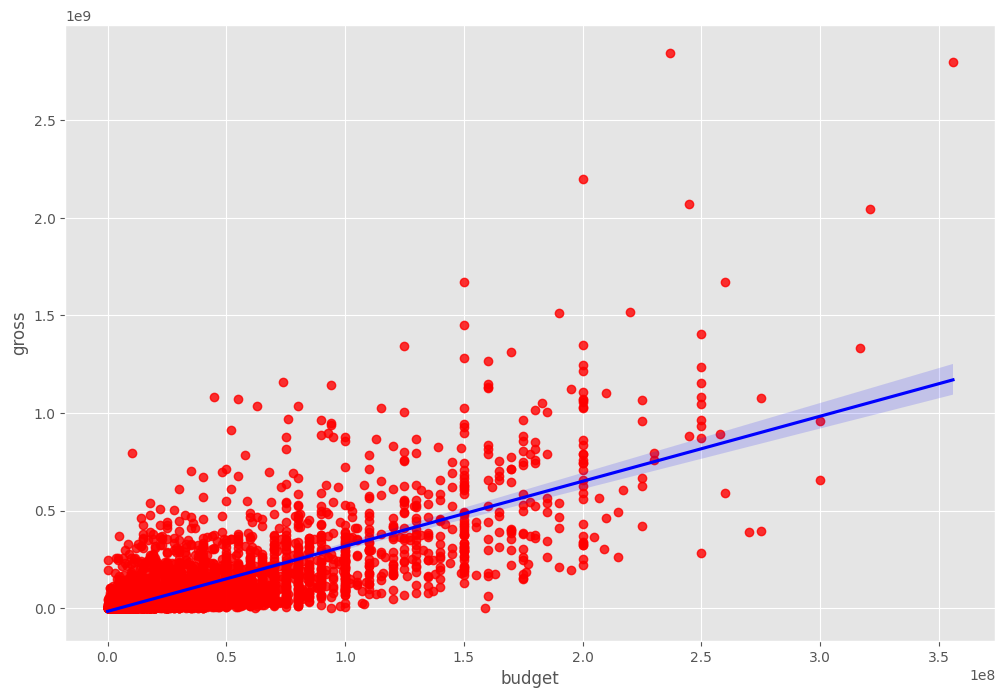

In [43]:
# Correlation - Budget Vs Gross with Seaborn (Reggplot)
sns.regplot(x='budget', y='gross', data=df, scatter_kws={'color': 'red'}, line_kws={'color': 'blue'})

In [44]:
# Correlation methods = pearson (def), kendall, spearman
df.corr(numeric_only=True)

,year,score,votes,budget,gross,runtime
year,1.000000,0.097995,0.222945,0.329321,0.257486,0.120811
score,0.097995,1.000000,0.409182,0.076254,0.186258,0.399451
votes,0.222945,0.409182,1.000000,0.442429,0.630757,0.309212
budget,0.329321,0.076254,0.442429,1.000000,0.740395,0.320447
gross,0.257486,0.186258,0.630757,0.740395,1.000000,0.245216
runtime,0.120811,0.399451,0.309212,0.320447,0.245216,1.000000


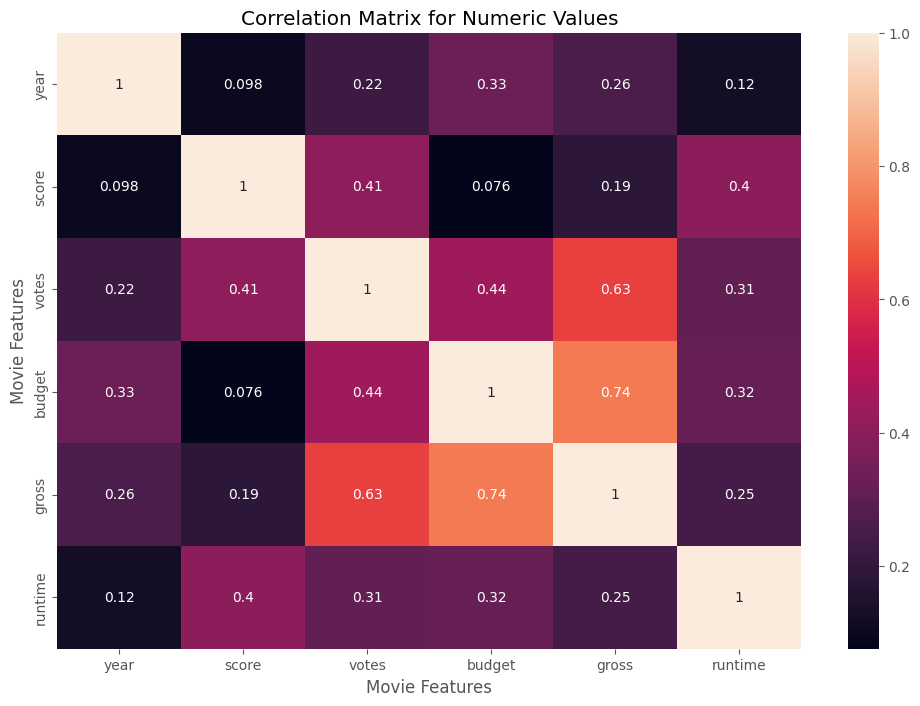

In [45]:
# correlation matrix  - High correlation is associated with color brightness
corr_matrix = df.corr(method='pearson', numeric_only=True)
sns.heatmap(corr_matrix, annot=True)
plt.title('Correlation Matrix for Numeric Values')
plt.xlabel('Movie Features')
plt.ylabel('Movie Features')
plt.show()

# Graph showed high correlation between amount spent in producing movies
# and movie earnings

In [47]:
# assigning values to columns, to evaluate more correlations
df_numerized = df.copy()
for col in df_numerized.columns:
  if (df_numerized[col].dtype == 'object'):
    df_numerized[col] = df_numerized[col].astype('category')
    df_numerized[col] = df_numerized[col].cat.codes

df_numerized.head()

,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime
0,6587,6,6,1980,1705,8.4,927000.0,2589,4014,1047,54,19000000,46998772,2319,146.0
1,5573,6,1,1980,1492,5.8,65000.0,2269,1632,327,55,4500000,58853106,731,104.0
2,5142,4,0,1980,1771,8.7,1200000.0,1111,2567,1745,55,18000000,538375067,1540,124.0
3,286,4,4,1980,1492,7.7,221000.0,1301,2000,2246,55,3500000,83453539,1812,88.0
4,1027,6,4,1980,1543,7.3,108000.0,1054,521,410,55,6000000,39846344,1777,98.0


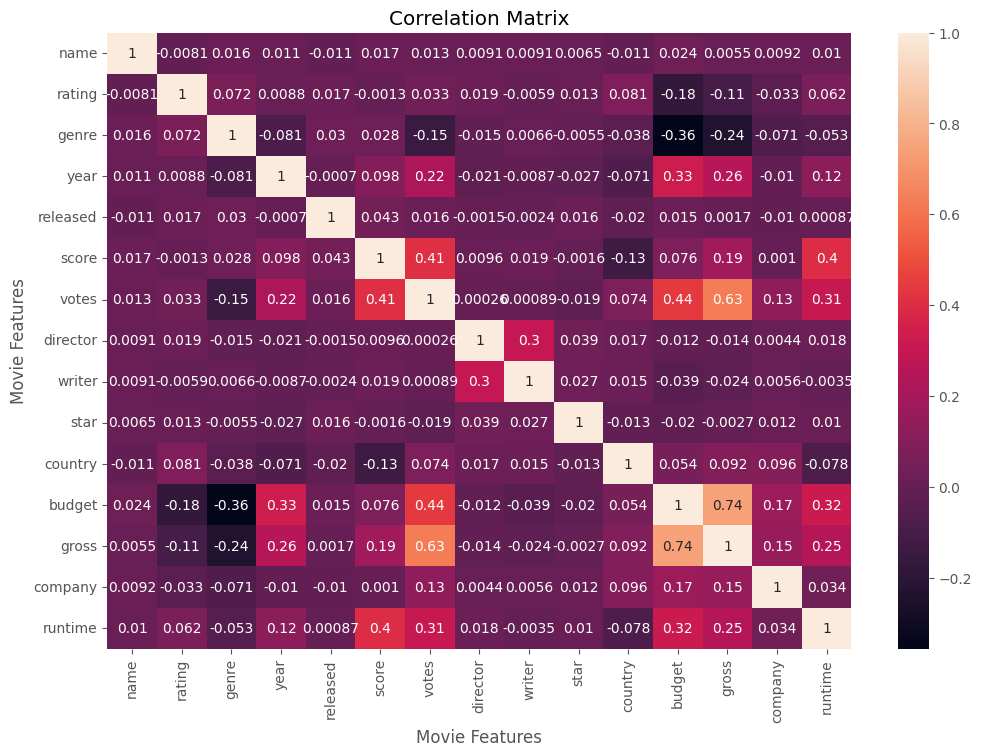

In [48]:
# correlation matrix  - High correlation is associated with color brightness
corr_matrix = df_numerized.corr()
sns.heatmap(corr_matrix, annot=True)
plt.title('Correlation Matrix')
plt.xlabel('Movie Features')
plt.ylabel('Movie Features')
plt.show()



In [30]:
# unstack the grid to isolate closely correlated pairs
corr_pairs = corr_matrix.unstack()
sorted_pairs = corr_pairs.sort_values()
high_corr = sorted_pairs[(sorted_pairs > 0.5) & (sorted_pairs < 1)]
high_corr

,,0
votes,gross,0.630757
gross,votes,0.630757
budget,gross,0.740395
gross,budget,0.740395


**Gross vs. Viewer Votes**
Higher box-office earnings strongly correlate with a higher number of user votes ($r \approx 0.6$).   
**Budget vs. Gross**
Higher production budgets strongly correlate with higher box-office gross ($r \approx 0.7$). Bigger budgets typically come with wider theatrical distribution and larger marketing campaigns, which drive total revenue.